<a href="https://colab.research.google.com/github/Shawntribuce1234/-ps1-starter.ipynb/blob/main/ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

My concrete household includes two young professionals in their mid 20s sharing a one bedroom apartment in Brooklyn, New York. One works in finance in Manhattan while the other works in tech. Both take the subway to work and spend most of their money on rent, groceries, transportation, eating out, shopping, and entertainment.


> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [5]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Apartment Rent",  "Price_2019": 2500, "Price_2024": 3400, "weight": 0.40},
    {"Item": "Groceries",       "Price_2019": 400,  "Price_2024": 550,  "weight": 0.15},
    {"Item": "Subway",          "Price_2019": 254,  "Price_2024": 264,  "weight": 0.05},
    {"Item": "Restaurants",     "Price_2019": 300,  "Price_2024": 450,  "weight": 0.10},
    {"Item": "Utilities",       "Price_2019": 150,  "Price_2024": 200,  "weight": 0.10},
    {"Item": "Entertainment",   "Price_2019": 200,  "Price_2024": 300,  "weight": 0.10},
    {"Item": "Shopping",        "Price_2019": 200,  "Price_2024": 260,  "weight": 0.05},
    {"Item": "Gym Membership",  "Price_2019": 100,  "Price_2024": 130,  "weight": 0.05}
]

In [6]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

8 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [11]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""

    # Calculate the weighted price change for each item
    index = sum(
        item["weight"] * (item[current_key] / item[base_key])
        for item in basket
    )

    # Multiply by 100 to make the base year equal to 100
    return index * 100


# 1) Calculate the unweighted average price change
unweighted = sum(
    (item["Price_2024"] / item["Price_2019"]) - 1
    for item in household_basket
) / len(household_basket) * 100


# 2) Calculate the weighted Laspeyres index
weighted_index = laspeyres(
    household_basket, "Price_2019", "Price_2024"
)

# Convert the index into a percentage increase
weighted_change = weighted_index - 100


# 3) Calculate the gap between the two inflation rates
gap = weighted_change - unweighted


print(f"Unweighted Average Price Change: {unweighted:.2f}%")
print(f"Weighted Laspeyres Index: {weighted_index:.2f}")
print(f"Weighted Price Change: {weighted_change:.2f}%")
print(f"Gap: {gap:.2f}")

Unweighted Average Price Change: 33.85%
Weighted Laspeyres Index: 136.56
Gap: 2.71


In [ ]:
# 1. the unweighted average price change across categories

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")

# 3. the gap between them

**Why do the two differ, and which would you defend to the client?**

*Your answer here.*
They differ because the unweighted average treats everything equally while the Laspeyres index takes into account how much money is spent on each category. I would defend the weighted index because it gives a more realistic picture of inflation for my NYC household.


---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [18]:
series_ids = [
    "CPIAUCSL",        # Overall inflation
    "CUSR0000SEHA",    # Rent
    "CUSR0000SAF11",   # Groceries
    "CUSR0000SETG",    # Public transportation
    "CUSR0000SEFV",    # Restaurants
    "CUSR0000SETA02",  # Used cars for comparison
    "CUSR0000SAH2",    # Household energy
    "CPIAPPSL"         # Apparel
]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | Helps compare my household's inflation to the national average.| Doesn't show the actual cost of living in NYC|
| `CUSR0000SEHA` | Rent takes up 40% of our budget, making it our biggest category.| Doesn't show the exact rent increases in Brooklyn.|
| `CUSR0000SAF11` | Helps track how much more we're spending on groceries.| Doesn't show the stores/brands we buy.|
| `CUSR0000SETG01` | Subway is an important cost factor. | Doesn't specifically track NYC subway fares.|
| `CUSR0000SEFV` | Eating out is a common occurance.| Doesn't reflect the restaurants we actually visit.|
| `CUSR0000SETA02` |Helps compare transportation inflation for people who drive. | Most households in the city don't own a car.|
| `CUSR0000SAH2` | Helps track changes in our monthly energy bills.| Doesn't include other household expenses.|
| `CUSR0000SAA` | Tracks how much is spent on clothing.| Doesn't include electronics or other shopping expenses.|

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [19]:
# Rebase to 2019 = 100

import pandas as pd
import matplotlib.pyplot as plt

# Use pandas dataframe to rebase FRED series
rebased_data = pd.DataFrame()

for series in series_ids:
    # Download the series from FRED
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    df = pd.read_csv(url)

    # Convert the date column to datetime
    df["observation_date"] = pd.to_datetime(df["observation_date"])

    # Keep observations from 2019 through 2024
    df = df[
        (df["observation_date"] >= "2019-01-01") &
        (df["observation_date"] <= "2024-12-31")
    ].copy()

    # Convert the price index to numeric values
    df[series] = pd.to_numeric(df[series], errors="coerce")

    # Calculate the average index value in 2019
    base_value = df.loc[
        df["observation_date"].dt.year == 2019, series
    ].mean()

    # Rebase the series so 2019 = 100
    df[series] = (df[series] / base_value) * 100

    # Store the rebased series
    df = df.set_index("observation_date")[[series]]
    rebased_data = rebased_data.join(df, how="outer")

# First five rows
print(rebased_data.head())

                   CPIAUCSL  CUSR0000SEHA  CUSR0000SAF11  CUSR0000SETG  \
observation_date                                                         
2019-01-01        98.790709     98.244554      99.923170     99.159379   
2019-02-01        99.087205     98.518166     100.142389     99.947016   
2019-03-01        99.461933     98.916503     100.295843     99.034528   
2019-04-01        99.835878     99.302155      99.773439     98.921238   
2019-05-01        99.860520     99.544057      99.948401     98.948212   

                  CUSR0000SEFV  CUSR0000SETA02  CUSR0000SAH2    CPIAPPSL  
observation_date                                                          
2019-01-01           98.583147      101.745372     99.958128  100.306441  
2019-02-01           98.932291      101.786867     99.743375  100.354795  
2019-03-01           99.113017      101.032795    100.243778   99.661726  
2019-04-01           99.433329      100.086270    100.235122   99.851111  
2019-05-01           99.642886 

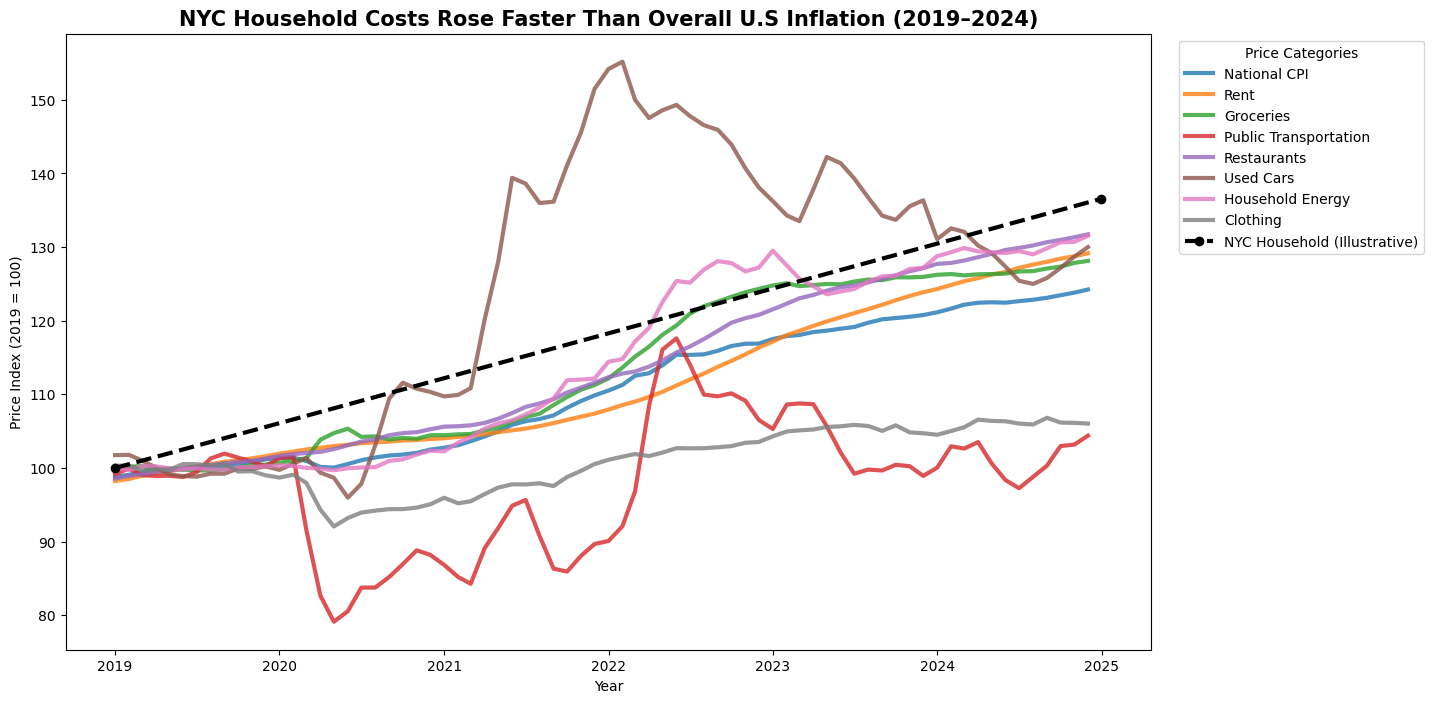

In [27]:
# One chart: every rebased series, plus your household index

# Calculate the household index for 2024
household_2024 = laspeyres(
    household_basket,
    "Price_2019",
    "Price_2024"
)

# Create a series with only the two observed household values
household_index = pd.Series(
    [100, household_2024],
    index=pd.to_datetime(["2019-01-01", "2024-12-31"]),
    name="NYC Household"
)
# Relabel FRED code names for legend
labels = {
    "CPIAUCSL": "National CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Groceries",
    "CUSR0000SETG": "Public Transportation",
    "CUSR0000SEFV": "Restaurants",
    "CUSR0000SETA02": "Used Cars",
    "CUSR0000SAH2": "Household Energy",
    "CPIAPPSL": "Clothing"
}

# Create the figure
plt.figure(figsize=(14, 8))

# Plot each rebased FRED series
for series in series_ids:
    plt.plot(
        rebased_data.index,
        rebased_data[series],
        label=labels[series],
        linewidth=3,
        alpha=0.8
    )

# Plot the household index separately
plt.plot(
    household_index.index,
    household_index.values,
    label="NYC Household (Illustrative)",
    color="black",
    linewidth=3,
    linestyle="--",
    marker="o"
)
plt.title(
    "NYC Household Costs Rose Faster Than Overall U.S Inflation (2019–2024)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Price Index (2019 = 100)")
plt.legend(
    title="Price Categories",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.


####Expectations:
Before running the audit I expect most of the FRED series to have
monthly observations without any missing months. Since this is an official
CPI series, I don't expect many gaps.


In [28]:
# First observation, last observation, frequency and missing months, for every series

# Empty list for the audit results
audit_results = []

for series in series_ids:

    # Data for current series
    s = rebased_data[series].dropna()

    # The first and last observations
    first = s.index.min()
    last = s.index.max()

    # Create a monthly grid
    monthly = s.asfreq("MS")

    # Months that are missing
    missing = monthly[monthly.isna()].index

    # Count the missing months
    missing_count = len(missing)
    audit_results.append({
        "Series": series,
        "First": first.strftime("%Y-%m"),
        "Last": last.strftime("%Y-%m"),
        "Frequency": "Monthly",
        "Missing months": missing_count
    })

# Put the results into a DataFrame
audit_df = pd.DataFrame(audit_results)
display(audit_df)

,Series,First,Last,Frequency,Missing months
0,CPIAUCSL,2019-01,2024-12,Monthly,0
1,CUSR0000SEHA,2019-01,2024-12,Monthly,0
2,CUSR0000SAF11,2019-01,2024-12,Monthly,0
3,CUSR0000SETG,2019-01,2024-12,Monthly,0
4,CUSR0000SEFV,2019-01,2024-12,Monthly,0
5,CUSR0000SETA02,2019-01,2024-12,Monthly,0
6,CUSR0000SAH2,2019-01,2024-12,Monthly,0
7,CPIAPPSL,2019-01,2024-12,Monthly,0


After checking all eight series I figured out that each one had monthly observations with zero missing months during the period I analyzed.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [ ]:
import pandas as pd

# Create Pandas dataframe of FRED series
full_data = pd.DataFrame()

for series in series_ids:
    # Download data
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    df = pd.read_csv(url)

    # Convert dates and prices to the correct types
    df["observation_date"] = pd.to_datetime(df["observation_date"])
    df[series] = pd.to_numeric(df[series], errors="coerce")

    # Store each series using its observation dates
    s = df.set_index("observation_date")[series]

    full_data = full_data.join(s, how="outer")


# Find the first and last observation for each series
start_dates = full_data.apply(lambda s: s.first_valid_index())
end_dates = full_data.apply(lambda s: s.last_valid_index())

# Drop any missing values
common_data = full_data.dropna()

# Calculate the common sample
common_start = common_data.index.min()
common_end = common_data.index.max()

# Count the months in the common sample
common_months = len(common_data)

# Find the longest series
longest_series = full_data.count().idxmax()
longest_months = full_data[longest_series].count()

# Calculate how many months are discarded
discarded_months = longest_months - common_months

print(f"Start: {common_start:%Y-%m}")
print(f"End: {common_end:%Y-%m}")
print(f"Months: {common_months}")
print(f"Longest series: {longest_series}")
print(f"Months discarded: {discarded_months}")

In [ ]:
# Headline comparison: full history vs common sample

# The two series to compare
headline = "CPIAUCSL"
rent = "CUSR0000SEHA"

# Function to calculate total percentage change
def price_change(series):
    # Remove missing values
    s = series.dropna()

    # Calculate percentage change from first to last observation
    return ((s.iloc[-1] / s.iloc[0]) - 1) * 100


# Calculate changes using each series full history
full_headline = price_change(full_data[headline])
full_rent = price_change(full_data[rent])
full_gap = full_rent - full_headline


# Calculate changes using the common sample
common_headline = price_change(common_data[headline])
common_rent = price_change(common_data[rent])
common_gap = common_rent - common_headline


# Calculate how much the comparison changes
gap_difference = common_gap - full_gap


print("FULL HISTORY")
print(f"National CPI: {full_headline:.2f}%")
print(f"Rent: {full_rent:.2f}%")
print(f"Gap: {full_gap:.2f}")

print("\nCOMMON SAMPLE")
print(f"National CPI: {common_headline:.2f}%")
print(f"Rent: {common_rent:.2f}%")
print(f"Gap: {common_gap:.2f}")

print("\nDIFFERENCE")
print(f"Change in gap: {gap_difference:.2f}")

**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting the data assumes it's better to compare prices over the same time period even if that means losing some older data points. While not restricting assumes we can still make a fair comparison using each series'full history.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

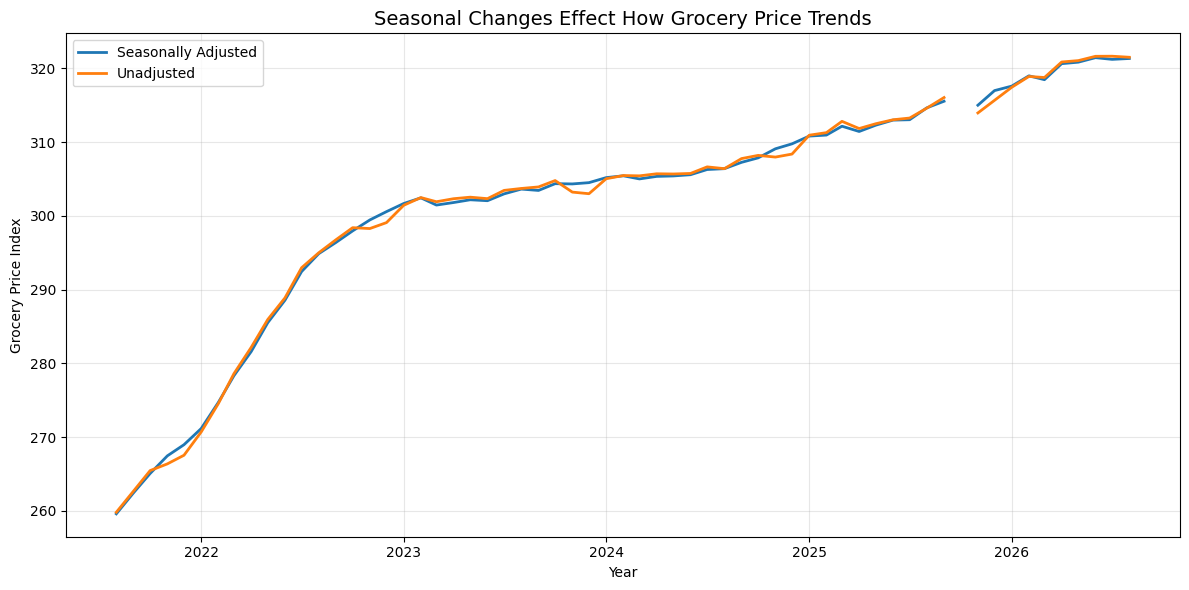

In [31]:
# Seasonally adjusted vs unadjusted, last five years
import pandas as pd
import matplotlib.pyplot as plt

# Filter the adjusted and unadjusted grocery series
series_pair = {
    "CUSR0000SAF11": "Seasonally Adjusted",
    "CUUR0000SAF11": "Unadjusted"
}

# Create an empty DataFrame to store both series
comparison_data = pd.DataFrame()

# Download both series from FRED
for series in series_pair:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    df = pd.read_csv(url)
    df["observation_date"] = pd.to_datetime(df["observation_date"])
    df[series] = pd.to_numeric(df[series], errors="coerce")     # Convert prices to numeric values
    df = df.set_index("observation_date") # Set the date as the index
    comparison_data[series] = df[series]  # Store the series


# Keep the last five years of available data
last_date = comparison_data.dropna(how="all").index.max()
start_date = last_date - pd.DateOffset(years=5)
comparison_data = comparison_data.loc[start_date:last_date]


# Create the chart
plt.figure(figsize=(12, 6))
for series in series_pair:
    plt.plot(
        comparison_data.index,
        comparison_data[series],
        label=series_pair[series],
        linewidth=2
    )
plt.title(
    "Seasonal Changes Effect How Grocery Price Trends",
    fontsize=14,
)

plt.xlabel("Year")
plt.ylabel("Grocery Price Index")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines are the seasonal adjustments throughout the year. I woudl use the unadjusted series though becuase it better represents the prices my NYC houshold will face when at the supermarket.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

In [ ]:
# Paste the AI's code here, run it, and correct it where it is wrong
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sensitivity_results = []

weight_range = np.linspace(0, 0.5, 51)

for i, item in enumerate(household_basket):

    for new_weight in weight_range:

        new_basket = [row.copy() for row in household_basket]

        other_weight = sum(
            row["weight"]
            for j, row in enumerate(household_basket)
            if j != i
        )

        new_basket[i]["weight"] = new_weight

        for j in range(len(new_basket)):
            if j != i:
                new_basket[j]["weight"] = (
                    household_basket[j]["weight"]
                    / other_weight
                ) * (1 - new_weight)

        new_index = laspeyres(
            new_basket,
            "Price_2019",
            "Price_2024"
        )

        sensitivity_results.append({
            "Category": item["Item"],
            "Weight": new_weight,
            "Index": new_index
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

plt.figure(figsize=(12, 7))

for category in sensitivity_df["Category"].unique():
    assert len(sensitivity_df[sensitivity_df["Category"] == category]) == 51

assert np.isclose(
    sum(item["weight"] for item in household_basket),
    1.0
)

print("Checks passed!")
    subset = sensitivity_df[
        sensitivity_df["Category"] == category
    ]

    plt.plot(
        subset["Weight"],
        subset["Index"],
        label=category,
        linewidth=2
    )

original_index = laspeyres(
    household_basket,
    "Price_2019",
    "Price_2024"
)

plt.axhline(
    original_index,
    color="black",
    linestyle="--",
    label="Original Household Index"
)

plt.title(
    "Household Inflation Changes as Spending Weights Shift",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Share of Household Spending")
plt.ylabel("Household Price Index (2019 = 100)")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
total_weight = sum(item["weight"] for item in household_basket)

print("Original weights:", total_weight)

assert np.isclose(total_weight, 1.0)

expected_rows = len(household_basket) * 51

print("Expected rows:", expected_rows)
print("Actual rows:", len(sensitivity_df))

assert len(sensitivity_df) == expected_rows

for _, row in sensitivity_df.iterrows():

    category = row["Category"]
    weight = row["Weight"]

    test_basket = [item.copy() for item in household_basket]

    selected = next(
        i for i, item in enumerate(test_basket)
        if item["Item"] == category
    )

    remaining_weight = sum(
        item["weight"]
        for i, item in enumerate(household_basket)
        if i != selected
    )

    for i, item in enumerate(test_basket):
        if i == selected:
            item["weight"] = weight
        else:
            item["weight"] = (
                household_basket[i]["weight"]
                / remaining_weight
            ) * (1 - weight)

    assert np.isclose(
        sum(item["weight"] for item in test_basket),
        1.0
    )

    assert np.isclose(
        laspeyres(test_basket, "Price_2019", "Price_2024"),
        row["Index"]
    )

print("All verification checks passed!")

In [ ]:
sensitivity_summary = (
    sensitivity_df
    .groupby("Category")["Index"]
    .agg(["min", "max"])
)

sensitivity_summary["Sensitivity"] = (
    sensitivity_summary["max"] - sensitivity_summary["min"]
)

sensitivity_summary = sensitivity_summary.sort_values(
    "Sensitivity",
    ascending=False
)

display(sensitivity_summary)

most_sensitive = sensitivity_summary.index[0]

print("Most sensitive category:", most_sensitive)

**What did the model get wrong, or get right in a way you had to check? Show the check.**

One thing I had to double check was whether the model correclty adjusted the other spending weights when changing one category. The rest of the code ran smoothly and didn't throw any errors which was great.

### AI Transcript

**Model: ChatGPT instant** &nbsp; **Date:10/13/2026**

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

Prompt:
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

### Task 4.2: The written finding (10 pts)

Between 2019 and 2024, our NYC household saw an estimated 36.6% increase in living costs, which was higher than the national inflation rate. One thing that stood out to me was how much rent contributed to our expenses, especially since it made up 40% of our household's budget.
When I compared our results with national CPI data, I noticed that inflation doesn't affect every household the same way. Our sensitivity analysis also showed that changing how much we spend on certain categories can change our overall inflation rate.
I have moderate confidence in our findings. While I checked our calculations and used official FRED data for comparison, our household prices were still estimates. Because of this, I think our index is useful for understanding how inflation might affect a household like ours, but it shouldn't replace official CPI data.

*Your finding here.*

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub